<a href="https://colab.research.google.com/github/odeepak/Lung-Cancer-Detection_CNN/blob/main/Lung_Cancer_Detection_using_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Lung Cancer Detection using Convolutional Neural Network (CNN)**

**Step 1: Importing Libraries**

In [1]:
import os
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn import metrics

import tensorflow as tf
from tensorflow import keras
from keras import layers

import warnings
warnings.filterwarnings('ignore')

**Step 2: Importing Dataset**
The dataset used is a custom subset (~2400images) containing three lung cancer categories

Normal (lung_n)
Adenocarcinoma (lung_aca)
Squamous cell carcinoma (lung_scc)

In [2]:
from google.colab import files

uploaded = files.upload()

Saving lung_subset_small_folder.zip to lung_subset_small_folder.zip


In [4]:
from zipfile import ZipFile
import os

data_path = '/content/lung_subset_small_folder.zip'

with ZipFile(data_path, 'r') as zip_ref:
    zip_ref.extractall('/content/')
    print('The data set has been extracted.')

The data set has been extracted.


**Step 3: Visualizing the Data**
We visualize random images from each category to understand the dataset.

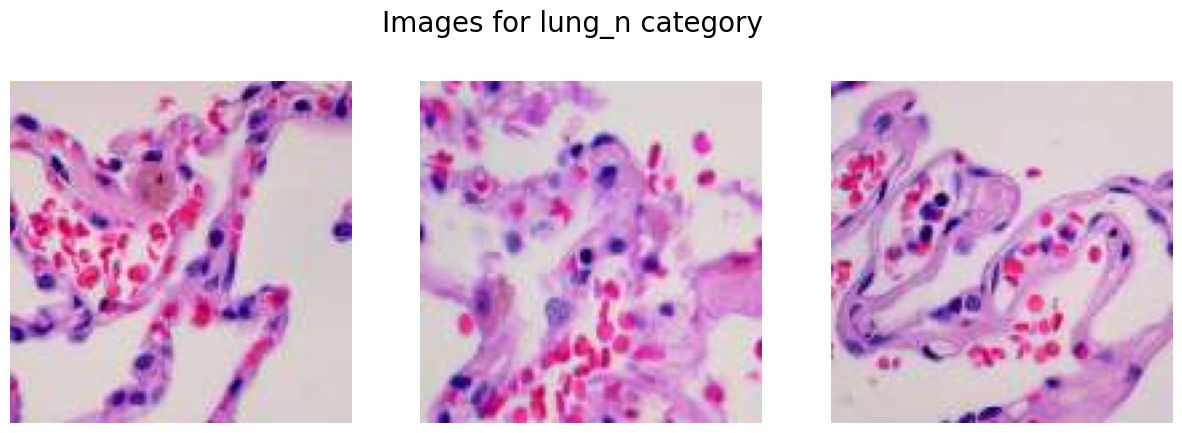

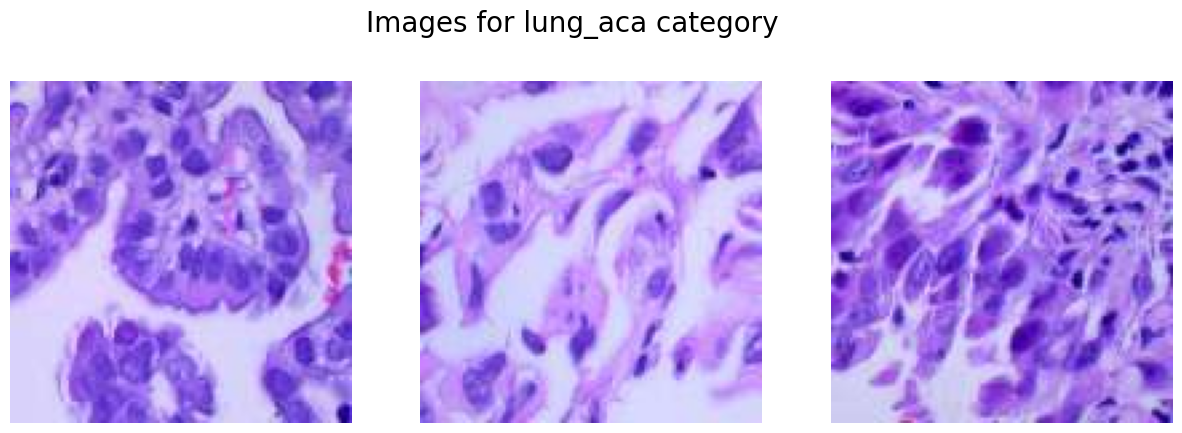

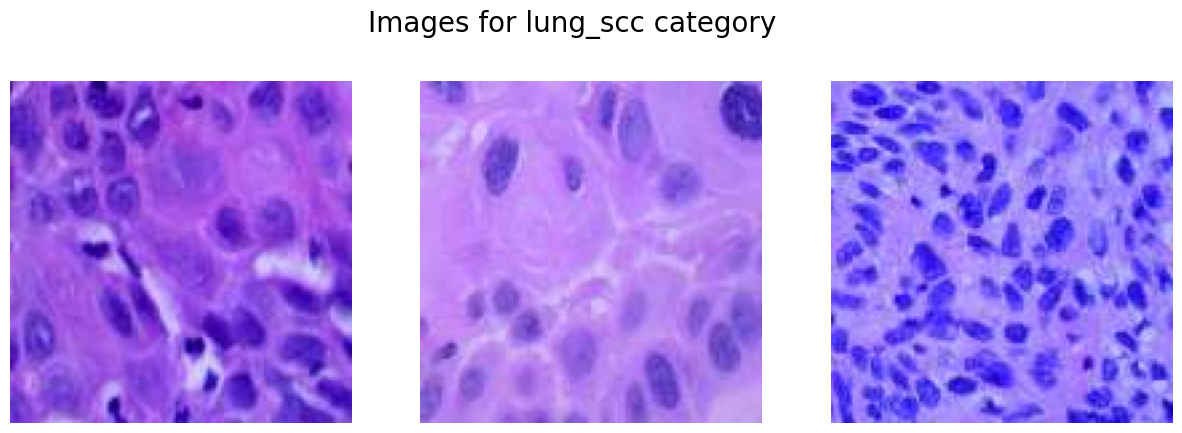

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

path = '/content/lung_subset_small_folder'

classes = ['lung_n', 'lung_aca', 'lung_scc']

for cat in classes:
    image_dir = f'{path}/{cat}'

    images = os.listdir(image_dir)

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'Images for {cat} category', fontsize=20)

    for i in range(3):
        k = np.random.randint(0, len(images))

        img = np.array(Image.open(f'{image_dir}/{images[k]}'))

        ax[i].imshow(img)
        ax[i].axis('off')

    plt.show()

**Step 4: Preparing the Dataset**
Instead of loading all images into memory, we use ImageDataGenerator to load images batch-by-batch.

Rescales pixel values
Splits data into training (80%) and validation (20%)
Prevents memory overflow

In [17]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)
train_data = datagen.flow_from_directory(
    path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training'
)
val_data = datagen.flow_from_directory(
    path,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation'
)
print("Classes:", train_data.class_indices)
print("Training Images:", train_data.samples)
print("Validation Images:", val_data.samples)
images, labels = next(train_data)

print("Image Shape:", images.shape)
print("Label Shape:", labels.shape)

Found 1920 images belonging to 3 classes.
Found 480 images belonging to 3 classes.
Classes: {'lung_aca': 0, 'lung_n': 1, 'lung_scc': 2}
Training Images: 1920
Validation Images: 480
Image Shape: (16, 128, 128, 3)
Label Shape: (16, 3)


**Step 5: Model Development**
we start building the CNN. Here, we use TensorFlow and Keras to define the architecture of our CNN model.

Sequential(): Builds a linear stack of layers.
Conv2D(): Applies convolution with specified filters, kernel size, ReLU activation and padding.
MaxPooling2D(): Downsamples feature maps by taking max values over pool size.
Flatten(): Converts 2D feature maps into 1D vector.
Dense(): Fully connected layer with given units and activation.
BatchNormalization(): Normalizes activations to speed up training.
Dropout(): Randomly drops neurons to reduce overfitting.
model.summary(): Displays model architecture details.

In [18]:
model = keras.models.Sequential([
    layers.Conv2D(32, (5, 5), activation='relu', padding='same', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.BatchNormalization(),
    layers.Dense(3, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,518,467 (32.50 MB)

 Trainable params: 8,517,699 (32.49 MB)

 Non-trainable params: 768 (3.00 KB)

**Step 6: Model Compilation**
the model architecture we will compile the model with an optimizer, loss function and evaluation metric then train it using the training data.

We use the Adam optimizer which adjusts the learning rate during training to speed up convergence.
Categorical cross entropy loss is appropriate as loss function for multi-class classification problems as it measures the difference between the predicted and actual probability distributions.
EarlyStopping: Stops training if validation accuracy doesn’t improve for a set number of epochs (patience).
ReduceLROnPlateau: Reduces learning rate when validation loss plateaus, controlled by patience and factor.
Custom myCallback class: Stops training early when validation accuracy exceeds 90%.
self.model.stop_training = True: Signals to stop training inside the callback.

In [19]:
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs.get('val_accuracy') > 0.90:
            print("Stopping early")
            self.model.stop_training = True

es = EarlyStopping(patience=3, monitor='val_accuracy', restore_best_weights=True)

lr = ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5)

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

**Step 7: Model Training**
The model is trained using generator-based data.

In [20]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    callbacks=[es, lr, myCallback()]
)

Epoch 1/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.7854 - loss: 0.5361 - val_accuracy: 0.3333 - val_loss: 11.8620 - learning_rate: 0.0010
Epoch 2/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 120s 1s/step - accuracy: 0.8562 - loss: 0.3652 - val_accuracy: 0.3562 - val_loss: 6.9311 - learning_rate: 0.0010
Epoch 3/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 113s 943ms/step - accuracy: 0.8625 - loss: 0.3569 - val_accuracy: 0.4833 - val_loss: 1.9274 - learning_rate: 0.0010
Epoch 4/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 113s 941ms/step - accuracy: 0.8781 - loss: 0.3306 - val_accuracy: 0.3354 - val_loss: 4.6028 - learning_rate: 0.0010
Epoch 5/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 113s 935ms/step - accuracy: 0.8797 - loss: 0.3049 - val_accuracy: 0.4021 - val_loss: 5.3426 - learning_rate: 0.0010
Epoch 6/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 117s 969ms/step - accuracy: 0.8948 - loss: 0.2663 - val_accuracy: 0.7917 - val_loss: 0.5434 - learning_rate: 5.0000e-04
Epoch 7/10
120/120 ━━━━━━━━━━━━━━━━━━━━ 114s 955ms/step - accurac

**Step 8: Visualizing**
Let's visualize the training and validation accuracy with each epoch.

pd.DataFrame(history.history) converts training history into a DataFrame.
history_df.loc[:, ['accuracy', 'val_accuracy']].plot() plots training and validation accuracy.

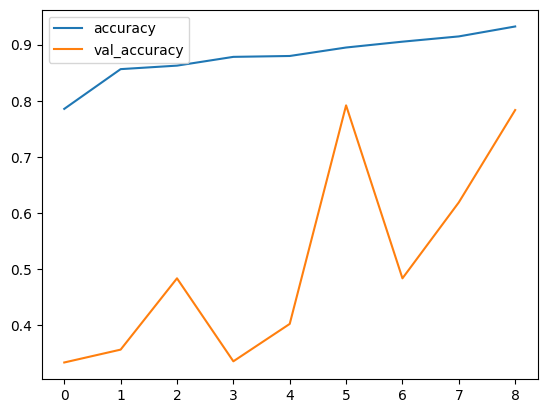

In [21]:
history_df = pd.DataFrame(history.history)
history_df.loc[:, ['accuracy', 'val_accuracy']].plot()
plt.show()

**Output:**

This graph shows the training and validation accuracy of the model over epochs. The training accuracy increases steadily reaching near 1.0 indicating the model is learning well from the training data. Although it's the case of overfitting



**Step 9: Model Evaluation**
We evaluate the model using predictions from validation data.

In [22]:
Y_pred = model.predict(val_data)
Y_pred_labels = np.argmax(Y_pred, axis=1)
Y_true = val_data.classes
from sklearn import metrics

print(metrics.classification_report(
    Y_true,
    Y_pred_labels,
    target_names=classes
))

30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 224ms/step
              precision    recall  f1-score   support

      lung_n       0.30      0.16      0.21       160
    lung_aca       0.32      0.29      0.31       160
    lung_scc       0.34      0.52      0.41       160

    accuracy                           0.33       480
   macro avg       0.32      0.33      0.31       480
weighted avg       0.32      0.33      0.31       480

